In [1]:
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict
from langchain_ollama import ChatOllama
from dotenv import load_dotenv

load_dotenv()



True

In [2]:
class SubState(TypedDict):
    input_text: str
    translated_text: str

In [3]:
subgraph_llm = ChatOllama(model="nemotron-3-nano:30b-cloud")


In [4]:
def translate_text(state: SubState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["input_text"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'translated_text': translated_text}

In [8]:
subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node("translate_text", translate_text)
subgraph_builder.add_edge(START,"translate_text")
subgraph_builder.add_edge("translate_text",END)

subgraph = subgraph_builder.compile()

# subgraph

In [9]:
class ParentState(TypedDict):
    question: str
    answer_eng: str
    answer_hin: str

In [10]:
parent_llm = ChatOllama(model="nemotron-3-nano:30b-cloud")

In [11]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [12]:
def translate_answer(state: ParentState):
    result= subgraph.invoke({
        "input_text": state["answer_eng"]
    })

    return {
        "answer_hin": result["translated_text"]
    }

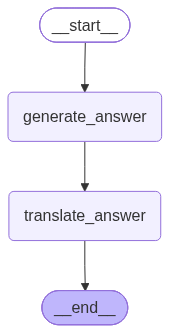

In [13]:
parent_builder= StateGraph(ParentState)
parent_builder.add_node("generate_answer",generate_answer)
parent_builder.add_node("translate_answer",translate_answer)
parent_builder.add_edge(START,"generate_answer")
parent_builder.add_edge("generate_answer","translate_answer")
parent_builder.add_edge("translate_answer",END)

graph = parent_builder.compile()

graph

In [14]:
graph.invoke({
    "question": "What is Agentic AI?"
})

{'question': 'What is Agentic AI?',
 'answer_eng': '**Agentic AI – a concise overview**\n\n---\n\n### 1. What the term means\n**Agentic AI** refers to artificial‑intelligence systems that act *as autonomous agents* rather than merely responding to a single input or following a fixed script.  \n- **Agency** = the capacity to **perceive** an environment, **make decisions**, and **take actions** to achieve goals, often while **learning** and **adapting** over time.  \n- In practice, an Agentic‑AI system combines:\n  1. **Sensing** (data collection from sensors, APIs, user input, etc.)  \n  2. **Reasoning/Planning** (Goal inference, strategy generation, evaluation)  \n  3. **Acting** (executing the chosen course of action via APIs, robotics, UI, etc.)  \n  4. **Learning & Feedback** (updating models or policies from outcomes)\n\nIn short, an Agentic AI is an **intelligent agent**—a software entity that pursues objectives and can operate semi‑autonomously in complex, dynamic settings.\n\n--